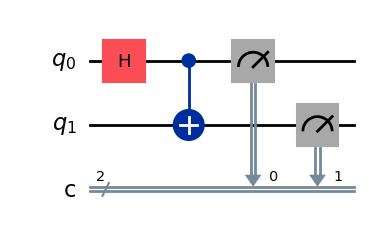

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Create a quantum circuit with 2 qubits and 2 classical bits
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1) # control on qubit 0 and target on qubit 1

# Measure both qubits
qc.measure([0, 1], [0, 1])

qc.draw(output="mpl")
#qc.draw(output="mpl")
#plt.show()

# Simulate the circuit using Qiskit Aer
# fig.savefig("bell_state_histogram.png") 

In [3]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)

# Get the statevector representing the quantum state
state = Statevector.from_instruction(qc)

print("Text format:")
print(state.draw(output="text"))

# Render the elegant LaTeX formula
state.draw(output="latex")


Text format:
[0.70710678+0.j,0.        +0.j,0.        +0.j,0.70710678+0.j]


<IPython.core.display.Latex object>

Measurement Counts: {'00': 487, '11': 537}

Plotting measurement histogram...


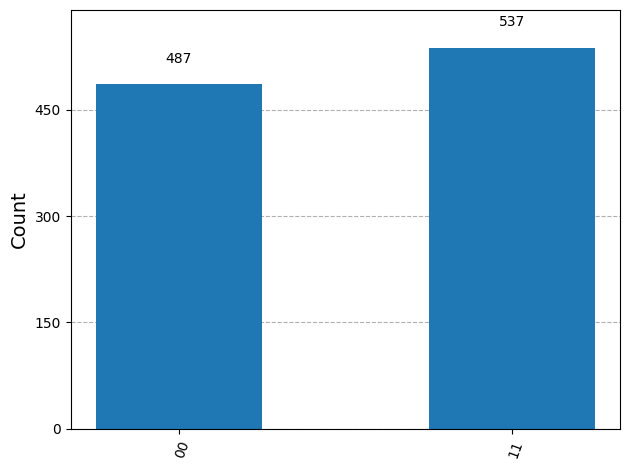

In [2]:
# Simulate the circuit using Qiskit Aer
backend = AerSimulator()
transpiled_qc = transpile(qc, backend)
job = backend.run(transpiled_qc, shots=1024)
counts = job.result().get_counts()

print("Measurement Counts:", counts)
print("\nPlotting measurement histogram...")

# Displays the interactive histogram bar chart 
plot_histogram(counts)

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(channel="ibm_quantum", token="YOUR_IBM_QUANTUM_TOKEN", overwrite=True)


In [ ]:
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime.executor_sampler import Sampler  # Client-side Sampler
from qiskit.visualization import plot_histogram

# 1. Connect to the IBM Quantum Service
service = QiskitRuntimeService()

# 2. Automatically find the least busy real hardware device available to you
backend = service.least_busy(operational=True, simulator=False)
print(f"Running on real system: {backend.name}")

# 3. Create the circuit (using measure_all is cleaner for primitives)
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0, 1)
qc.measure_all()

# 4. Transpile the circuit to map to the target backend's layout
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)

# 5. Run the hardware execution via Sampler
sampler = Sampler(backend=backend)
job = sampler.run([isa_circuit], shots=1024)
print(f"Job submitted! Job ID: {job.job_id()}")

result = job.result()

# 6. Extract counts and plot results
pub_result = result[0]
hardware_counts = pub_result.data.meas.get_counts()

print("Hardware Results:", hardware_counts)
fig = plot_histogram(hardware_counts)
fig.savefig("hardware_bell_state.png")
